<a href="https://colab.research.google.com/github/RolandoRobledo/Equipo-programacion-para-inteligencia-artificial/blob/main/Actividad_fundamental_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PpIA: Actividad fundamental 2

Equipo

Rolando Robledo Garcia 2182694

Angel Dario Reyes Garza 2194347

Ethan Raul Leos Rodriguez 2190405

Ruben Alejandro Garcia Zalpa 2188593

Gonzalo Isaias Mora Garcia 2276161





Ejercicio 1.1.- Limpieza y Manipulación con Pandas


Primero importamos las librerías Pandas y NumPy para la manipulación e inspección de datos, después cargamos el dataset y hacemos uso de funciones para eliminar valores nulos, si es que los hay, para luego crear una nueva columna.

In [121]:
#Importamos librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [122]:
#Cargar dataset real (Vino tinto)
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(url, sep=';')

#Mostrar las primeras 5 filas y el resumen estadístico.
print("¡Dataset cargado con éxito!")
print(df.head())
print("Resumen estadistico: ")
print(df.describe())

#Identificar y eliminar valores nulos
print("Valores nulos: ")
print(df.isnull().sum())
df = df.dropna()
print("Valores nulos después de limpiar los datos:")
print(df.isnull().sum())

#Crear uan nueva columna
df["is_good"] = (df["quality"] > 6).astype(int)

#Filtra el DataFrame para mostrar solo los vinos con un nivel de alcohol superior al 11%
df_vino_mayor_alcohol = df[df["alcohol"] > 11]
print(df_vino_mayor_alcohol)

¡Dataset cargado con éxito!
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8    

1.2.- Operaciones Matemáticas con NumPy


Creamos la matriz solo usando los valores de X (features), excluyendo los de Y (Target), después hacemos uso de la librería NumPy para hacer operaciones matemáticas y normalizar los valores en la matriz que creamos.

In [123]:
#Creamos la matriz sin incluir Y (Target)
X = df.drop(columns=["quality", "is_good"]).to_numpy()
print(X)
print(X.shape)

#Normalizacion Z-Score
media=np.mean(X)
desviacion_estandar=np.std(X)
X_normalizada = (X - media) / desviacion_estandar
print("\nPrimeras 5 filas normalizadas:")
print(X_normalizada[:5])

[[ 7.4    0.7    0.    ...  3.51   0.56   9.4  ]
 [ 7.8    0.88   0.    ...  3.2    0.68   9.8  ]
 [ 7.8    0.76   0.04  ...  3.26   0.65   9.8  ]
 ...
 [ 6.3    0.51   0.13  ...  3.42   0.75  11.   ]
 [ 5.9    0.645  0.12  ...  3.57   0.71  10.2  ]
 [ 6.     0.31   0.47  ...  3.39   0.66  11.   ]]
(1599, 11)

Primeras 5 filas normalizadas:
[[-0.04389548 -0.44445665 -0.48630632 -0.37271435 -0.48176264  0.17133142
   1.54639215 -0.4266526  -0.2764601  -0.45282658  0.07567502]
 [-0.01998138 -0.4336953  -0.48630632 -0.33086467 -0.48044737  1.0083249
   3.51930537 -0.42671239 -0.29499353 -0.44565235  0.09958912]
 [-0.01998138 -0.44086953 -0.48391491 -0.34880025 -0.48080608  0.41047241
   2.74209713 -0.42670043 -0.29140641 -0.44744591  0.09958912]
 [ 0.18328847 -0.46956645 -0.45282658 -0.37271435 -0.48182243  0.53004291
   3.10080862 -0.42664064 -0.29738494 -0.45163088  0.09958912]
 [-0.04389548 -0.44445665 -0.48630632 -0.37271435 -0.48176264  0.17133142
   1.54639215 -0.4266526  -0.2764601

Ejercicio 1.3.- Visualización de Insights con Matplotlib

1. Histograma


Hacemos uso de las funciones de Matplotlib para generar un histograma de los valores de la columna de alcohol del dataset.

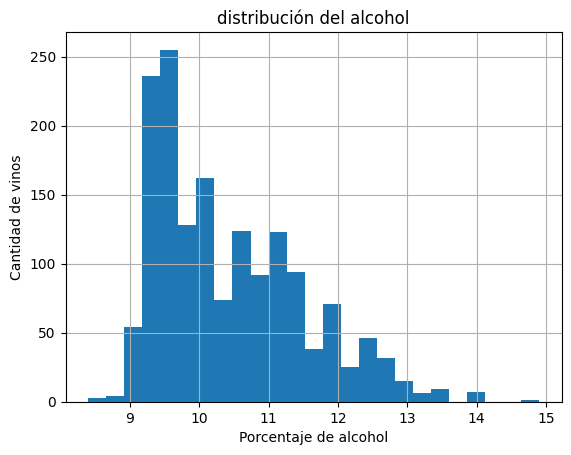

In [124]:
df["alcohol"].hist(bins=25)
plt.title("distribución del alcohol")
plt.xlabel("Porcentaje de alcohol")
plt.ylabel("Cantidad de vinos")
plt.show()


2. Scatter Plot


Siguiendo en uso de la librería de Matplotlib, generamos una gráfica de dispersión de la relación del pH y la acidez fija del vino.

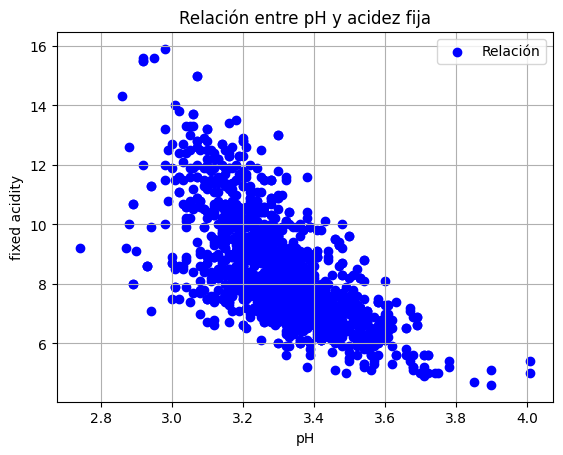

In [125]:

plt.scatter(df["pH"], df["fixed acidity"], color='blue', label="Relación")
plt.title("Relación entre pH y acidez fija")
plt.xlabel("pH")
plt.legend()
plt.ylabel("fixed acidity")
plt.grid(True)
plt.show()

¿Notas alguna tendencia?

Sí se puede notar una tendencia y es que, en cuanto el pH aumenta, fixed acidity disminuye, notándose una relación inversa entre ambas variables, aun cuando existen puntos con una dispersión ligera, la tendencia sí es notable.

3. Boxplot


Primero usamos la función sorted() y .unique() en "quality" para conocer las distintas calidades y que estén ordenadas, después utilizamos un ciclo for para, por cada calidad, agrupar el porcentaje de alcohol de los vinos que tengan el valor de esa calidad, después, haciendo uso de las funciones de Matplotlib, graficamos nuestro gráfico de cajas.

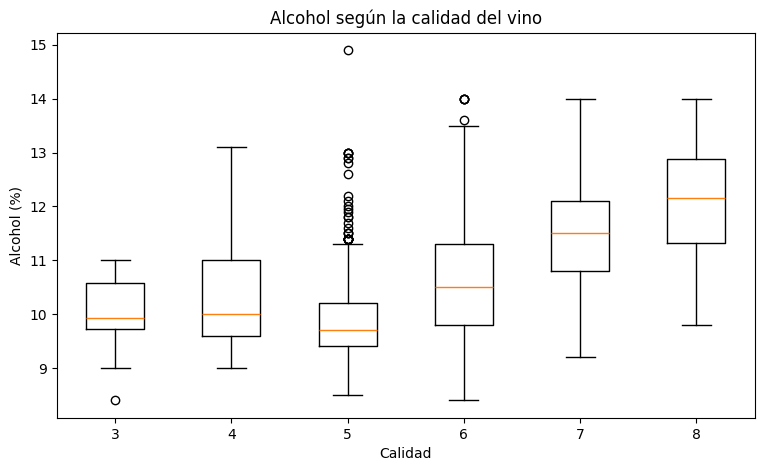

In [126]:
#Obtener las calidades existentes
calidades = sorted(df["quality"].unique())
datos = []

#Agrupar los vinos
for calidad in calidades:
    grupo = df.loc[df["quality"] == calidad, "alcohol"]
    datos.append(grupo)

#Crear boxplot
plt.figure(figsize=(9, 5))
plt.boxplot(datos)
plt.xticks(range(1, len(calidades) + 1), calidades)
plt.title("Alcohol según la calidad del vino")
plt.xlabel("Calidad")
plt.ylabel("Alcohol (%)")

plt.show()

Ejercicio 2.1.- Análisis Exploratorio con Pandas

Primero cargamos el dataset y lo asignamos a la variable penguins, después determinamos cuántas filas tienen valores nulos y eliminamos las filas en las cuales existan valores nulos en datos críticos. Posteriormente, hacemos un cálculo del promedio de la masa de cada pingüino, pero separando por grupos usando la función groupby(), haciendo que tengamos la media de la masa por especie e isla. Después creamos un subconjunto de la especie Gentoo que pesen más de 5000 g, para lo cual utilizamos operadores de comparación y el operador lógico and.

In [127]:
# URL del dataset de pingüinos de Palmer
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"

# Cargar los datos
penguins= pd.read_csv(url)

# Mostrar los primeros registros para confirmar
print("Dataset cargado correctamente:")
print(penguins.head())

#Determinar cuantas filas tienen valores nulos y eliminar valores nulos criticos
print("\n Nuero de filas con nulos:", penguins.isna().any(axis=1).sum())
print("\n Filas con nulos antes: \n", penguins.isnull().sum())
penguins = penguins.dropna(subset=["body_mass_g", "bill_length_mm", "bill_depth_mm"])
print(" \n Filas con nulos despues: \n",penguins.isnull().sum())

# Calculamos la masa corporal (body_mass_g) promedio por cada especie y por isla.
print(penguins.groupby(["species", "island"])["body_mass_g"].mean())

#Creamos un subconjunto para especie gentoo que pesen mas de 5000g
gentoo = penguins[(penguins["species"] == "Gentoo") & (penguins["body_mass_g"]> 5000)]
print(" \nPrimeras 5 filas del subconjunto de la especie gentoo: \n")
print(gentoo.head())

Dataset cargado correctamente:
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  
0       3750.0    MALE  
1       3800.0  FEMALE  
2       3250.0  FEMALE  
3          NaN     NaN  
4       3450.0  FEMALE  

 Nuero de filas con nulos: 11

 Filas con nulos antes: 
 species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
 
 Filas con nulos despues: 
 species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_lengt

Ejercicio 2.2.- Procesamiento de Señales con NumPy

Creamos una matriz con los tamaños de los picos "bill_length_mm" y "bill_depth_mm". Después imprimimos las primeras 5 filas para comprobar los datos y, usando .shape, vemos el tamaño de la matriz, que quedaría de N x 2. Después dividimos los valores de la columna de longitud entre los de profundidad para encontrar la proporción de los picos. Posteriormente, calculamos la media y la desviación estándar para establecer una condición con un límite inferior y uno superior, ubicados a 2 desviaciones estándar respecto a la media.

In [128]:
#Creamos la matriz
matriz_bill = penguins[["bill_length_mm", "bill_depth_mm"]].to_numpy()
print("Primeras 5 filas de la matriz de bill_length_mm y bill_depth_mm")
print(matriz_bill[:5])
print("Dimensiones de la matriz: ", matriz_bill.shape )


proporcion_de_picos = matriz_bill[:, 0] / matriz_bill[:, 1]
print("\nProporción de los primeros 5 picos: \n", proporcion_de_picos[:5])

#Calculamos outliers de mas de 2 desviaciones de la media en el largo del pico
Largo_pico=matriz_bill[:,0]
media_largo=np.mean(Largo_pico)
desviacion_largo=np.std(Largo_pico)
outliers=Largo_pico[(Largo_pico < media_largo-2*desviacion_largo) | (Largo_pico > media_largo + 2 *desviacion_largo )]
print("\nLos valores atipicos son: ", outliers)

pinguinos_pares=matriz_bill[::2]
print("\nPinguinos pares (primeras 5 filas):\n", pinguinos_pares[:5])

Primeras 5 filas de la matriz de bill_length_mm y bill_depth_mm
[[39.1 18.7]
 [39.5 17.4]
 [40.3 18. ]
 [36.7 19.3]
 [39.3 20.6]]
Dimensiones de la matriz:  (342, 2)

Proporción de los primeros 5 picos: 
 [2.09090909 2.27011494 2.23888889 1.9015544  1.90776699]

Los valores atipicos son:  [32.1 58.  55.8 59.6 55.9 55.1]

Pinguinos pares (primeras 5 filas):
 [[39.1 18.7]
 [40.3 18. ]
 [39.3 20.6]
 [39.2 19.6]
 [42.  20.2]]


Ejercicio 2.3.- Visualización Científica con Matplotlib

Primero creamos una gráfica de dispersión de la relación que tienen las aletas con la masa corporal, diferenciando cada especie por color, haciendo uso de un ciclo for y la función groupby(). Después, buscamos el pingüino más pesado con .idxmax() y usamos la función annotate() para indicarlo en la gráfica. Por último, creamos 2 gráficos, en este caso, 2 histogramas: uno para la masa corporal y otro para la longitud de las aletas, haciendo uso de otra función conocida, la cual es subplots().

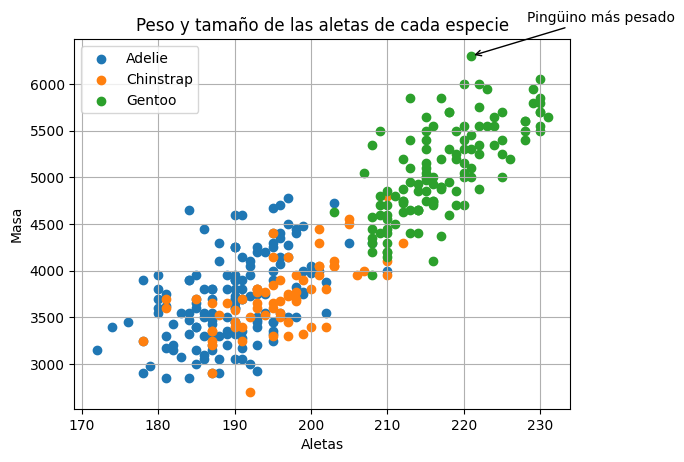

Text(0, 0.5, 'Cantidad de pinguinos')

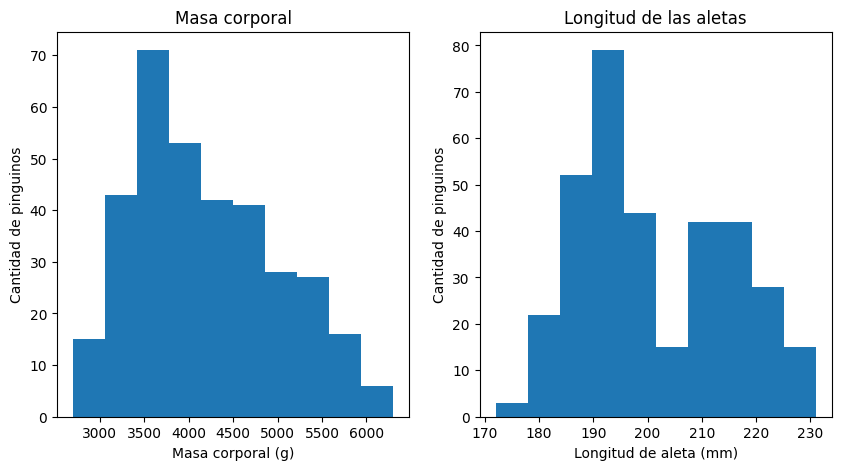

In [129]:
#Grafico de disperción de masa y longitud de las aletas
for especie, pinguino in penguins.groupby("species"):
    plt.scatter(pinguino["flipper_length_mm"], pinguino["body_mass_g"], label=especie)

pinguino_mas_grande=penguins.loc[penguins["body_mass_g"].idxmax()]
plt.annotate("Pingüino más pesado", xy=(pinguino_mas_grande["flipper_length_mm"], pinguino_mas_grande["body_mass_g"]), xytext=(40, 25), textcoords="offset points", arrowprops={"arrowstyle": "->"})

plt.title("Peso y tamaño de las aletas de cada especie")
plt.xlabel("Aletas")
plt.ylabel("Masa")
plt.legend()
plt.grid(True)
plt.show()

#Grafico subplot de la masa y tamaño de las aletas por separado
fig, axs=plt.subplots(1 ,2, figsize=(10, 5))
#primer grafico
axs[0].hist(penguins["body_mass_g"])
axs[0].set_title("Masa corporal")
axs[0].set_xlabel("Masa corporal (g)")
axs[0].set_ylabel("Cantidad de pinguinos")

axs[1].hist(penguins["flipper_length_mm"])
axs[1].set_title("Longitud de las aletas")
axs[1].set_xlabel("Longitud de aleta (mm)")
axs[1].set_ylabel("Cantidad de pinguinos")
